# Credit Card Fraud
**AI I used:** Claude Sonnet 5.5 through Claude


## 1. Loading the data
**Prompt:** *"I've got a csv called card_transdata.csv with credit card transactions (distance from home, distance from last transaction, ratio to median purchase price, repeat retailer, used chip, used pin, online order, fraud). Can you give me the pandas code to import what I need, load it, and show the first few rows?"*

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

tx_raw = pd.read_csv("card_transdata.csv")
tx_raw.head()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0
1,10.829943,0.175592,1.294219,1.0,NaN,0.0,0.0,0
2,5.091079,NaN,0.427715,1.0,0.0,0.0,1.0,0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0


## 2. Getting a feel for the data
**Prompt:** *"How many rows and columns does it have? What are the data types and how many non-null values per column? Can I also see summary stats?"*

In [2]:
tx_raw.shape

(999, 8)

In [3]:
tx_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 8 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   distance_from_home              999 non-null    float64
 1   distance_from_last_transaction  996 non-null    float64
 2   ratio_to_median_purchase_price  997 non-null    float64
 3   repeat_retailer                 992 non-null    float64
 4   used_chip                       995 non-null    float64
 5   used_pin_number                 997 non-null    float64
 6   online_order                    995 non-null    float64
 7   fraud                           999 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 62.6 KB


In [4]:
tx_raw.describe().round(2)

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
count,999.00,996.00,997.00,992.00,995.00,997.00,995.00,999.00
mean,26.88,5.44,1.66,0.89,0.31,0.12,0.67,0.08
std,63.90,35.67,2.35,0.31,0.46,0.32,0.47,0.27
min,0.10,0.00,0.02,0.00,0.00,0.00,0.00,0.00
25%,3.99,0.31,0.47,1.00,0.00,0.00,0.00,0.00
50%,10.34,0.96,0.96,1.00,0.00,0.00,1.00,0.00
75%,25.39,3.14,1.92,1.00,1.00,0.00,1.00,0.00
max,965.91,990.07,36.07,1.00,1.00,1.00,1.00,1.00


So 999 rows and 8 columns. Some columns have fewer than 999 non-null values, which means there's missing data I need to deal with. Also the distance columns have huge max values compared to their medians, so those are probably really skewed.

## 3. Cleaning: missing values
**Prompt:** *"Which columns have missing values, and how many? Show count and percent. If it's only a small chunk of the data, drop those rows and tell me how many got removed."*

In [5]:
missing = pd.DataFrame({
    "missing_count": tx_raw.isna().sum(),
    "missing_pct": (tx_raw.isna().mean() * 100).round(2),
})
missing

,missing_count,missing_pct
distance_from_home,0,0.0
distance_from_last_transaction,3,0.3
ratio_to_median_purchase_price,2,0.2
repeat_retailer,7,0.7
used_chip,4,0.4
used_pin_number,2,0.2
online_order,4,0.4
fraud,0,0.0


In [6]:
tx = tx_raw.dropna().copy()
print(f"Rows before: {len(tx_raw)}")
print(f"Rows after:  {len(tx)}")
print(f"Rows dropped: {len(tx_raw) - len(tx)} ({(len(tx_raw) - len(tx)) / len(tx_raw):.1%})")
tx.head()

Rows before: 999
Rows after:  977
Rows dropped: 22 (2.2%)


,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0
5,5.586408,13.261073,0.064768,1.0,0.0,0.0,0.0,0
6,3.724019,0.956838,0.278465,1.0,0.0,0.0,1.0,0


Only 22 rows (about 2.2%) were missing something, so I just dropped them. That's not enough to mess up the results. I'm using `tx` (the cleaned version) from here on.

## 4. Looking at one variable at a time
**Prompt:** *"Make a countplot of the fraud column so I can see how balanced it is, and print the exact counts and percents too."*

fraud
0    901
1     76
Name: count, dtype: int64
fraud
0    92.2
1     7.8
Name: proportion, dtype: float64


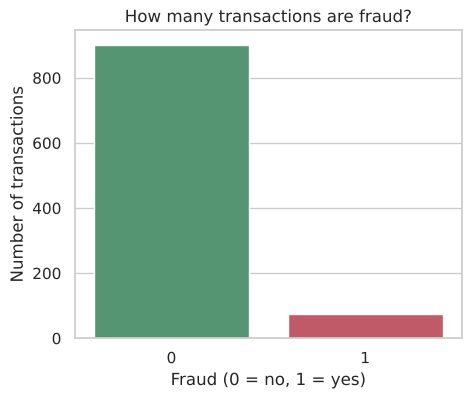

In [7]:
print(tx["fraud"].value_counts())
print((tx["fraud"].value_counts(normalize=True) * 100).round(1))

plt.figure(figsize=(5, 4))
sns.countplot(data=tx, x="fraud", hue="fraud", palette=["#4c9f70", "#d1495b"], legend=False)
plt.title("How many transactions are fraud?")
plt.xlabel("Fraud (0 = no, 1 = yes)")
plt.ylabel("Number of transactions")
plt.show()

Fraud is pretty rare here: 76 fraud vs 901 not fraud, so about 7.8%. That's super imbalanced, which is a big deal if we ever build a model (a model that always says "not fraud" would still be right about 92% of the time lol).

**Prompt:** *"Do the same countplot for used_pin_number and repeat_retailer, side by side."*

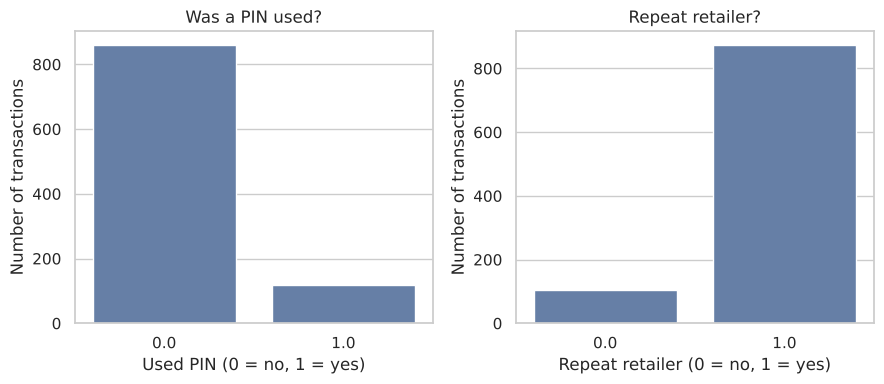

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
sns.countplot(data=tx, x="used_pin_number", ax=axes[0], color="#5b7db1")
axes[0].set_title("Was a PIN used?")
axes[0].set_xlabel("Used PIN (0 = no, 1 = yes)")
sns.countplot(data=tx, x="repeat_retailer", ax=axes[1], color="#5b7db1")
axes[1].set_title("Repeat retailer?")
axes[1].set_xlabel("Repeat retailer (0 = no, 1 = yes)")
for a in axes:
    a.set_ylabel("Number of transactions")
plt.tight_layout()
plt.show()

Most transactions didn't use a PIN (860 out of 977), and most were at a retailer the person had already bought from (874 out of 977).

**Prompt (the exercise):** *"Same thing but for online_order, so I can see how many were online vs not."*

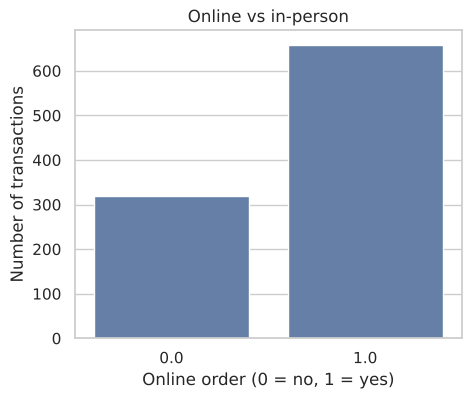

In [9]:
plt.figure(figsize=(5, 4))
sns.countplot(data=tx, x="online_order", color="#5b7db1")
plt.title("Online vs in-person")
plt.xlabel("Online order (0 = no, 1 = yes)")
plt.ylabel("Number of transactions")
plt.show()

About two thirds of the transactions (658 of 977) were online orders.

**Prompt:** *"Make a histogram of ratio_to_median_purchase_price with a reasonable number of bins."*

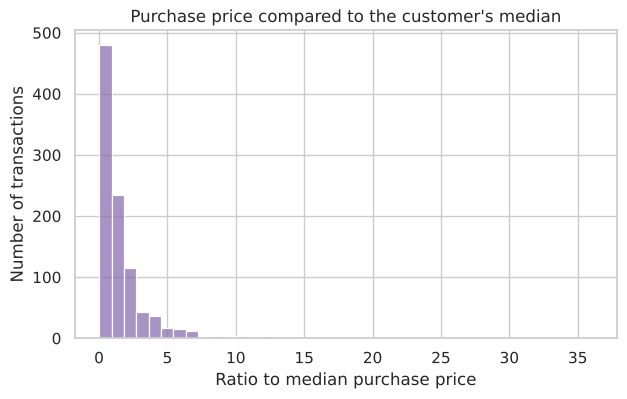

In [10]:
plt.figure(figsize=(7, 4))
sns.histplot(tx["ratio_to_median_purchase_price"], bins=40, color="#8a6fb0")
plt.title("Purchase price compared to the customer's median")
plt.xlabel("Ratio to median purchase price")
plt.ylabel("Number of transactions")
plt.show()

Almost everything is bunched up around 1 (so a normal purchase for that person), then there's a long tail of a few giant purchases, with the biggest being about 36x their median. Really right-skewed.

**Prompt (the exercise):** *"Now a histogram for distance_from_home. If it's really skewed, also show a version that makes it easier to read."*

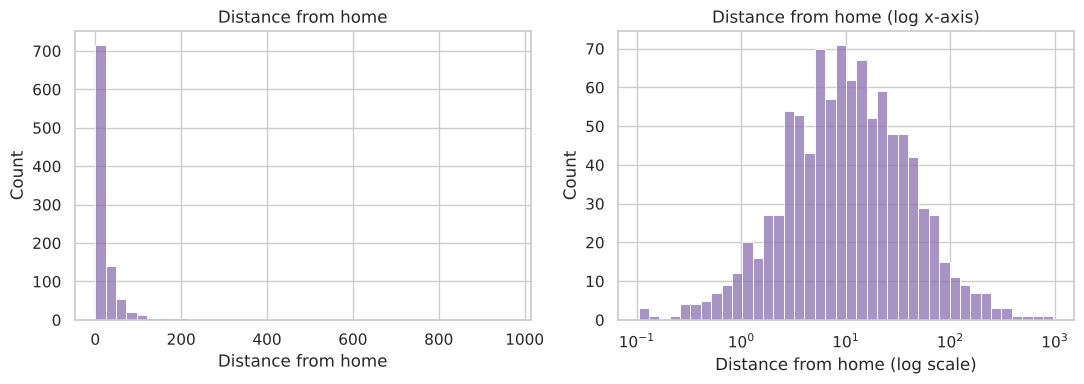

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(tx["distance_from_home"], bins=40, color="#8a6fb0", ax=axes[0])
axes[0].set_title("Distance from home")
axes[0].set_xlabel("Distance from home")
sns.histplot(tx["distance_from_home"], bins=40, log_scale=True, color="#8a6fb0", ax=axes[1])
axes[1].set_title("Distance from home (log x-axis)")
axes[1].set_xlabel("Distance from home (log scale)")
plt.tight_layout()
plt.show()

The normal histogram is basically one giant bar on the left because a few transactions are almost 1,000 away from home (the median is only about 10). The log version on the right spreads it out so you can actually see the shape.

## 5. Comparing fraud vs not fraud
Looking at one variable at a time doesn't really say what separates fraud from normal transactions, so now I split things up by the fraud column.

**Prompt:** *"For used_pin_number, make two plots next to each other: (1) a countplot split by fraud and (2) a stacked bar showing the percent of transactions that were fraud in each PIN group. Green for not fraud, red for fraud. Then turn it into a function so I can reuse it on the other yes/no columns."*

Fraud rate by Used PIN:
used_pin_number
0.0    8.8%
1.0    0.0%
Name: fraud, dtype: str


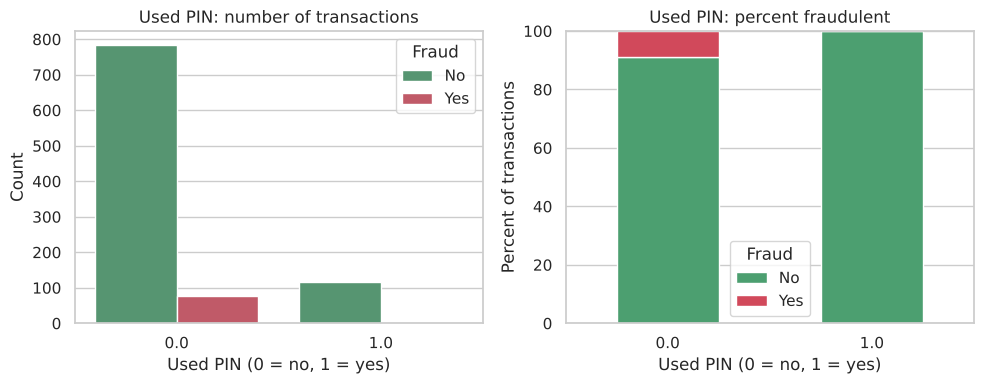

In [12]:
FRAUD_COLORS = {0: "#4c9f70", 1: "#d1495b"}

def fraud_breakdown(df, col, label):
    """Counts and within-group percentages of fraud for a 0/1 column."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    sns.countplot(data=df, x=col, hue="fraud", palette=FRAUD_COLORS, ax=axes[0])
    axes[0].set_title(f"{label}: number of transactions")
    axes[0].set_xlabel(f"{label} (0 = no, 1 = yes)")
    axes[0].set_ylabel("Count")
    axes[0].legend(title="Fraud", labels=["No", "Yes"])

    pct = pd.crosstab(df[col], df["fraud"], normalize="index") * 100
    pct.plot(kind="bar", stacked=True, color=[FRAUD_COLORS[0], FRAUD_COLORS[1]], ax=axes[1], rot=0)
    axes[1].set_title(f"{label}: percent fraudulent")
    axes[1].set_xlabel(f"{label} (0 = no, 1 = yes)")
    axes[1].set_ylabel("Percent of transactions")
    axes[1].legend(title="Fraud", labels=["No", "Yes"])

    plt.tight_layout()
    plt.show()

    print(f"Fraud rate by {label}:")
    print((df.groupby(col)["fraud"].mean() * 100).round(1).astype(str) + "%")

fraud_breakdown(tx, "used_pin_number", "Used PIN")

Wow, zero fraud out of the 117 transactions where a PIN was used. Without a PIN the fraud rate is about 8.8%. So a PIN looks really protective here (though 117 isn't a huge sample).

**Prompt:** *"Run that same function on used_chip."*

Fraud rate by Used chip:
used_chip
0.0    9.4%
1.0    4.3%
Name: fraud, dtype: str


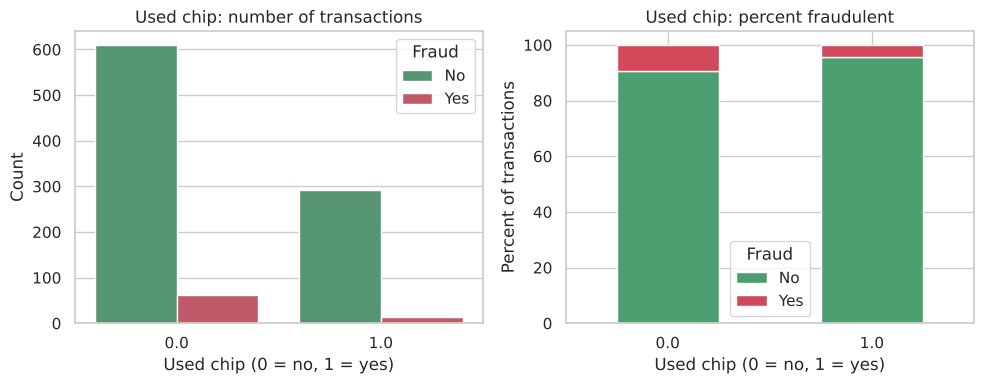

In [13]:
fraud_breakdown(tx, "used_chip", "Used chip")

Chip transactions are fraud about 4.3% of the time vs about 9.4% with no chip. So chip helps, just not as much as a PIN.

**Prompt (the exercise):** *"Run it on online_order too."*

Fraud rate by Online order:
online_order
0.0     0.6%
1.0    11.2%
Name: fraud, dtype: str


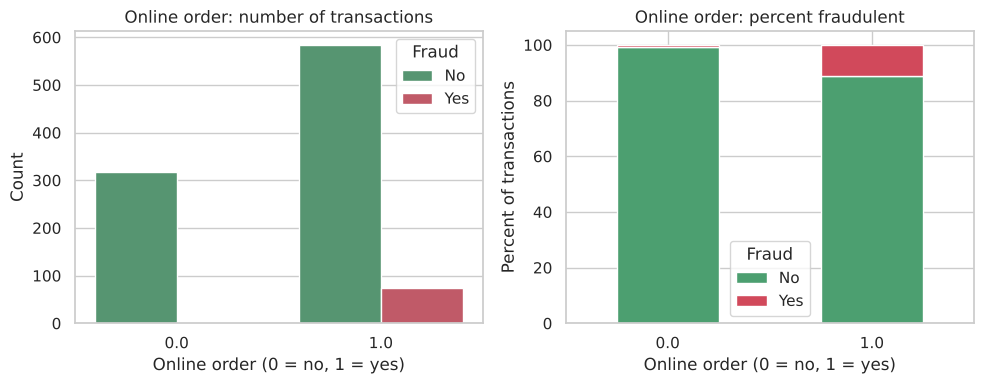

In [14]:
fraud_breakdown(tx, "online_order", "Online order")

This one is the biggest gap so far. About 11.2% of online orders are fraud, but only about 0.6% of in-person ones (just 2 out of 319). Online orders seem way riskier.

**Prompt (extra, I wanted to check all four):** *"Do the same for repeat_retailer."*

Fraud rate by Repeat retailer:
repeat_retailer
0.0    4.9%
1.0    8.1%
Name: fraud, dtype: str


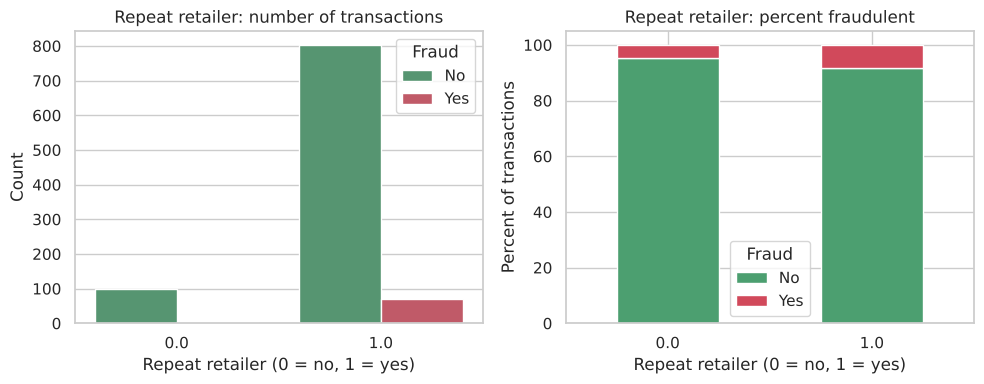

In [15]:
fraud_breakdown(tx, "repeat_retailer", "Repeat retailer")

This one surprised me. Repeat retailers actually have a slightly higher fraud rate (about 8.1%) than new retailers (about 4.9%), which is the opposite of what I expected. But there are only 103 non-repeat transactions, so I wouldn't read too much into it.

**Prompt:** *"Compare the three numeric columns for fraud vs not fraud using medians, since they're so skewed."*

In [16]:
num_cols = ["distance_from_home", "distance_from_last_transaction", "ratio_to_median_purchase_price"]
tx.groupby("fraud")[num_cols].median().round(2)

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price
fraud,,,
0,9.68,0.96,0.88
1,18.95,0.91,4.88


The median price ratio for fraud is about 4.9 compared to about 0.9 for normal transactions, so fraud tends to be way bigger purchases than usual. Fraud also tends to be farther from home.

## 6. Scatter plots
**Prompt (the exercise):** *"Make a scatter plot with distance_from_last_transaction on x and ratio_to_median_purchase_price on y, colored by fraud. Make the fraud points easy to spot since there are so few."*

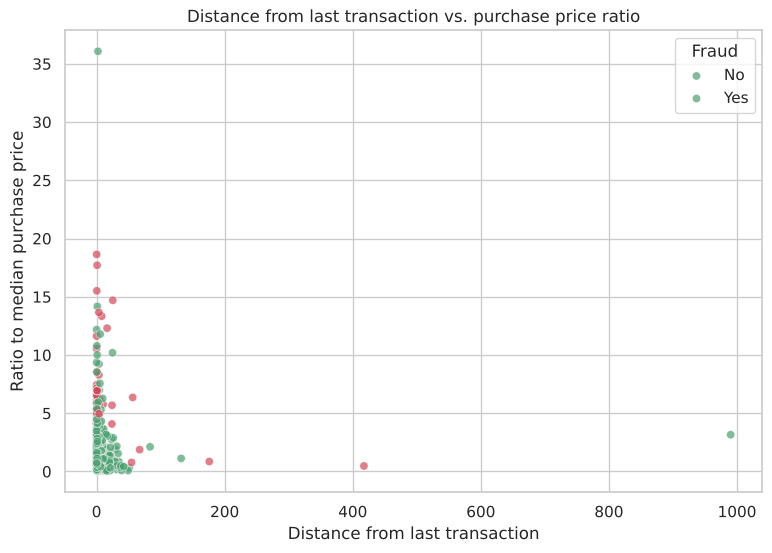

In [17]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=tx,
    x="distance_from_last_transaction",
    y="ratio_to_median_purchase_price",
    hue="fraud",
    palette=FRAUD_COLORS,
    alpha=0.7,
)
plt.title("Distance from last transaction vs. purchase price ratio")
plt.xlabel("Distance from last transaction")
plt.ylabel("Ratio to median purchase price")
plt.legend(title="Fraud", labels=["No", "Yes"])
plt.show()

The red (fraud) dots are mostly higher up on the price ratio axis, but they're spread out across all the distances from last transaction. So distance from last transaction by itself doesn't really separate fraud from not fraud.

**Prompt:** *"Same scatter plot but with distance_from_home on the x-axis."*

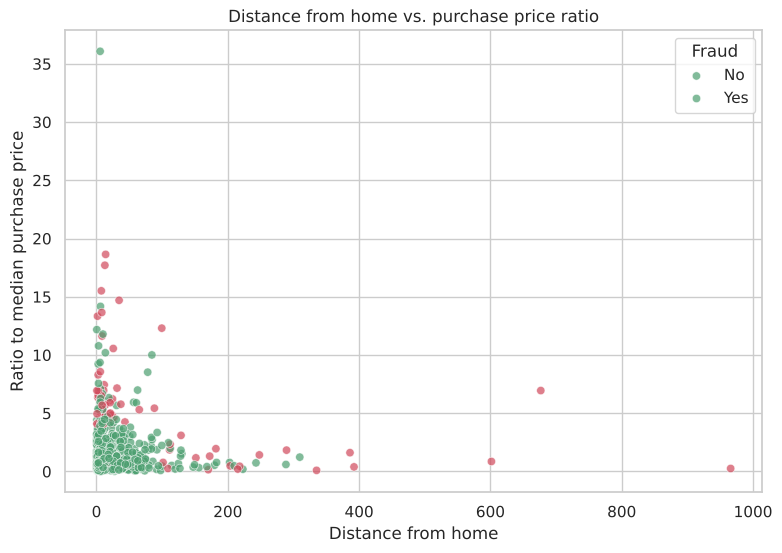

In [18]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=tx,
    x="distance_from_home",
    y="ratio_to_median_purchase_price",
    hue="fraud",
    palette=FRAUD_COLORS,
    alpha=0.7,
)
plt.title("Distance from home vs. purchase price ratio")
plt.xlabel("Distance from home")
plt.ylabel("Ratio to median purchase price")
plt.legend(title="Fraud", labels=["No", "Yes"])
plt.show()